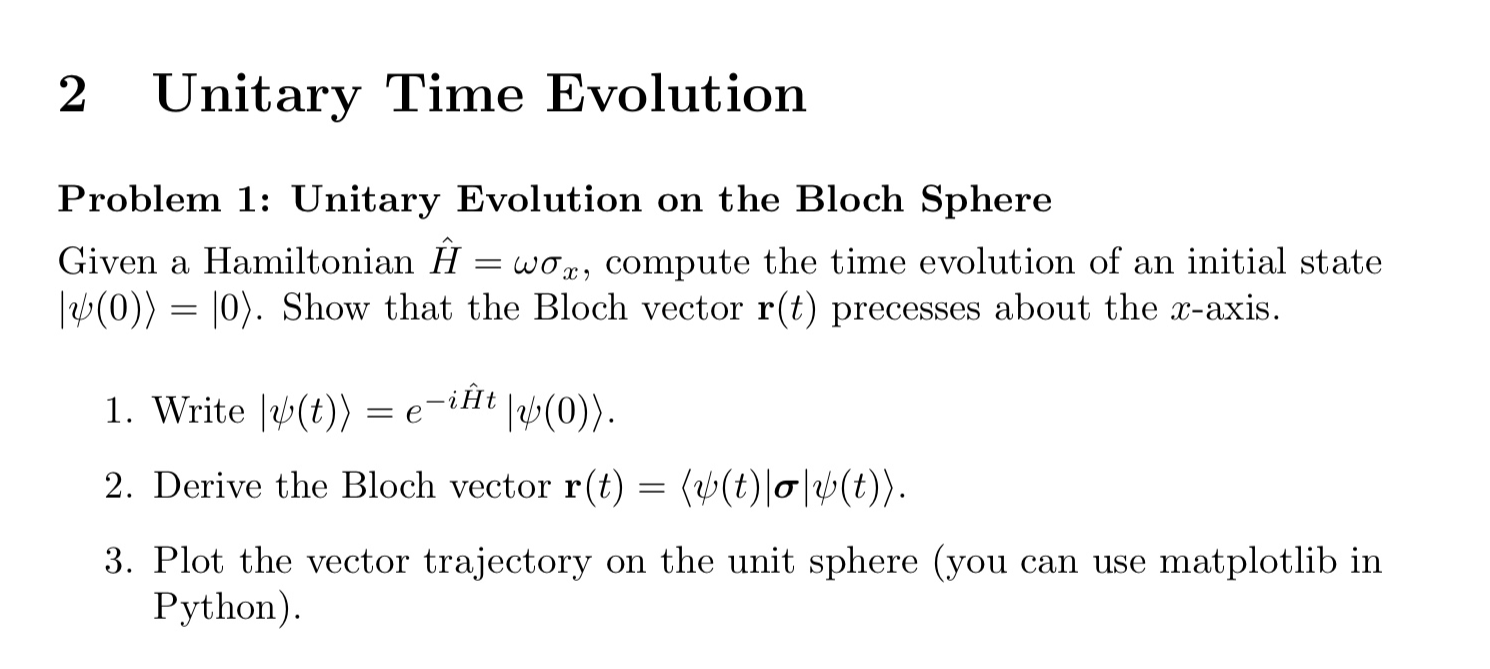

1.1
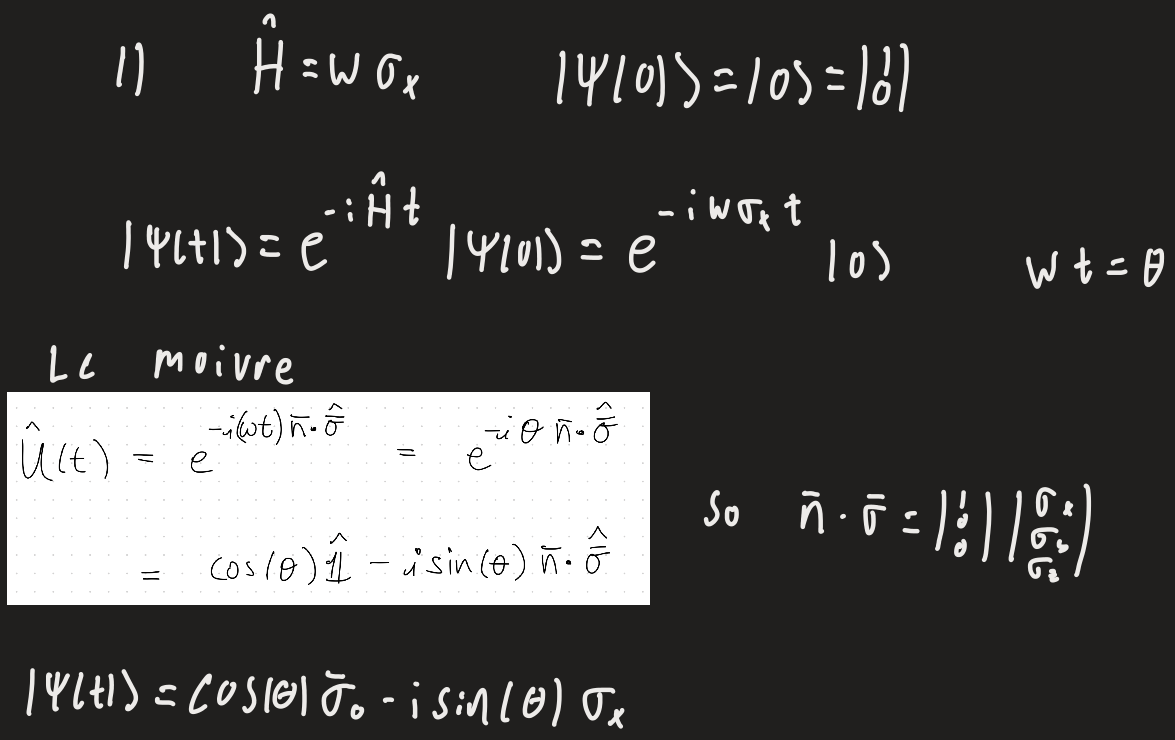

In [36]:
import numpy as np
import matplotlib.pyplot as plt
from qutip import sigmax, sigmay, sigmaz, qeye, basis, expect
from qutip import sesolve
from qutip import tensor, entropy_vn, concurrence

In [37]:
sx, sy, sz = sigmax(), sigmay(), sigmaz()
I  = qeye(2)          # 2x2 identitet
ket0 = basis(2, 0)    # |0> basis (2,0) betyder at det er en 2-dimensionel vektor og vi vælger den første basisvektor
ket1 = basis(2, 1)    # |1> basis (2,1) betyder at det er en 2-dimensionel vektor og vi vælger den anden basisvektor
ket_plus = (ket0 + ket1).unit()  # |+> basis
ket_minus = (ket0 - ket1).unit() # |-> basis

In [38]:
psi_0=tensor(ket_plus,ket_plus)  # initial state
M= tensor(sx,I)+tensor(sz,sz)  # Hamiltonian
(-1j*M).expm() *psi_0

Quantum object: dims=[[2, 2], [1]], shape=(4, 1), type='ket', dtype=Dense
Qobj data =
[[0.07797185-6.98455999e-01j]
 [0.07797185+0.00000000e+00j]
 [0.07797185+5.55111512e-17j]
 [0.07797185-6.98455999e-01j]]

In [39]:
t=1
w=1/t
theta=w*t*np.sqrt(2)
N= (tensor(sx,I)+tensor(sz,sz))/np.sqrt(2)
def moivre(theta,sigma):
    return (np.cos(theta) * tensor(qeye(2), qeye(2)) - 1j * np.sin(theta) * sigma)
moivre(theta, N)*psi_0 #moivre operatoren for theta=1 og sigma=sx

Quantum object: dims=[[2, 2], [1]], shape=(4, 1), type='ket', dtype=Dense
Qobj data =
[[0.07797185-0.698456j]
 [0.07797185+0.j      ]
 [0.07797185+0.j      ]
 [0.07797185-0.698456j]]

In [40]:

N*psi_0 # initial state

Quantum object: dims=[[2, 2], [1]], shape=(4, 1), type='ket', dtype=Dense
Qobj data =
[[0.70710678]
 [0.        ]
 [0.        ]
 [0.70710678]]

In [41]:
tensor(ket_minus,ket_minus)  # initial state

Quantum object: dims=[[2, 2], [1]], shape=(4, 1), type='ket', dtype=Dense
Qobj data =
[[ 0.5]
 [-0.5]
 [-0.5]
 [ 0.5]]

In [42]:
for k in ket0, ket1, ket_plus, ket_minus:
    #print the states in the computational basis and with their names
    print(tensor(k,k).full(), k)

[[1.+0.j]
 [0.+0.j]
 [0.+0.j]
 [0.+0.j]] Quantum object: dims=[[2], [1]], shape=(2, 1), type='ket', dtype=Dense
Qobj data =
[[1.]
 [0.]]
[[0.+0.j]
 [0.+0.j]
 [0.+0.j]
 [1.+0.j]] Quantum object: dims=[[2], [1]], shape=(2, 1), type='ket', dtype=Dense
Qobj data =
[[0.]
 [1.]]
[[0.5+0.j]
 [0.5+0.j]
 [0.5+0.j]
 [0.5+0.j]] Quantum object: dims=[[2], [1]], shape=(2, 1), type='ket', dtype=Dense
Qobj data =
[[0.70710678]
 [0.70710678]]
[[ 0.5+0.j]
 [-0.5+0.j]
 [-0.5+0.j]
 [ 0.5-0.j]] Quantum object: dims=[[2], [1]], shape=(2, 1), type='ket', dtype=Dense
Qobj data =
[[ 0.70710678]
 [-0.70710678]]


check de to giver det samme. Den skriver det som en matrice med z=a+bi hvor i=j
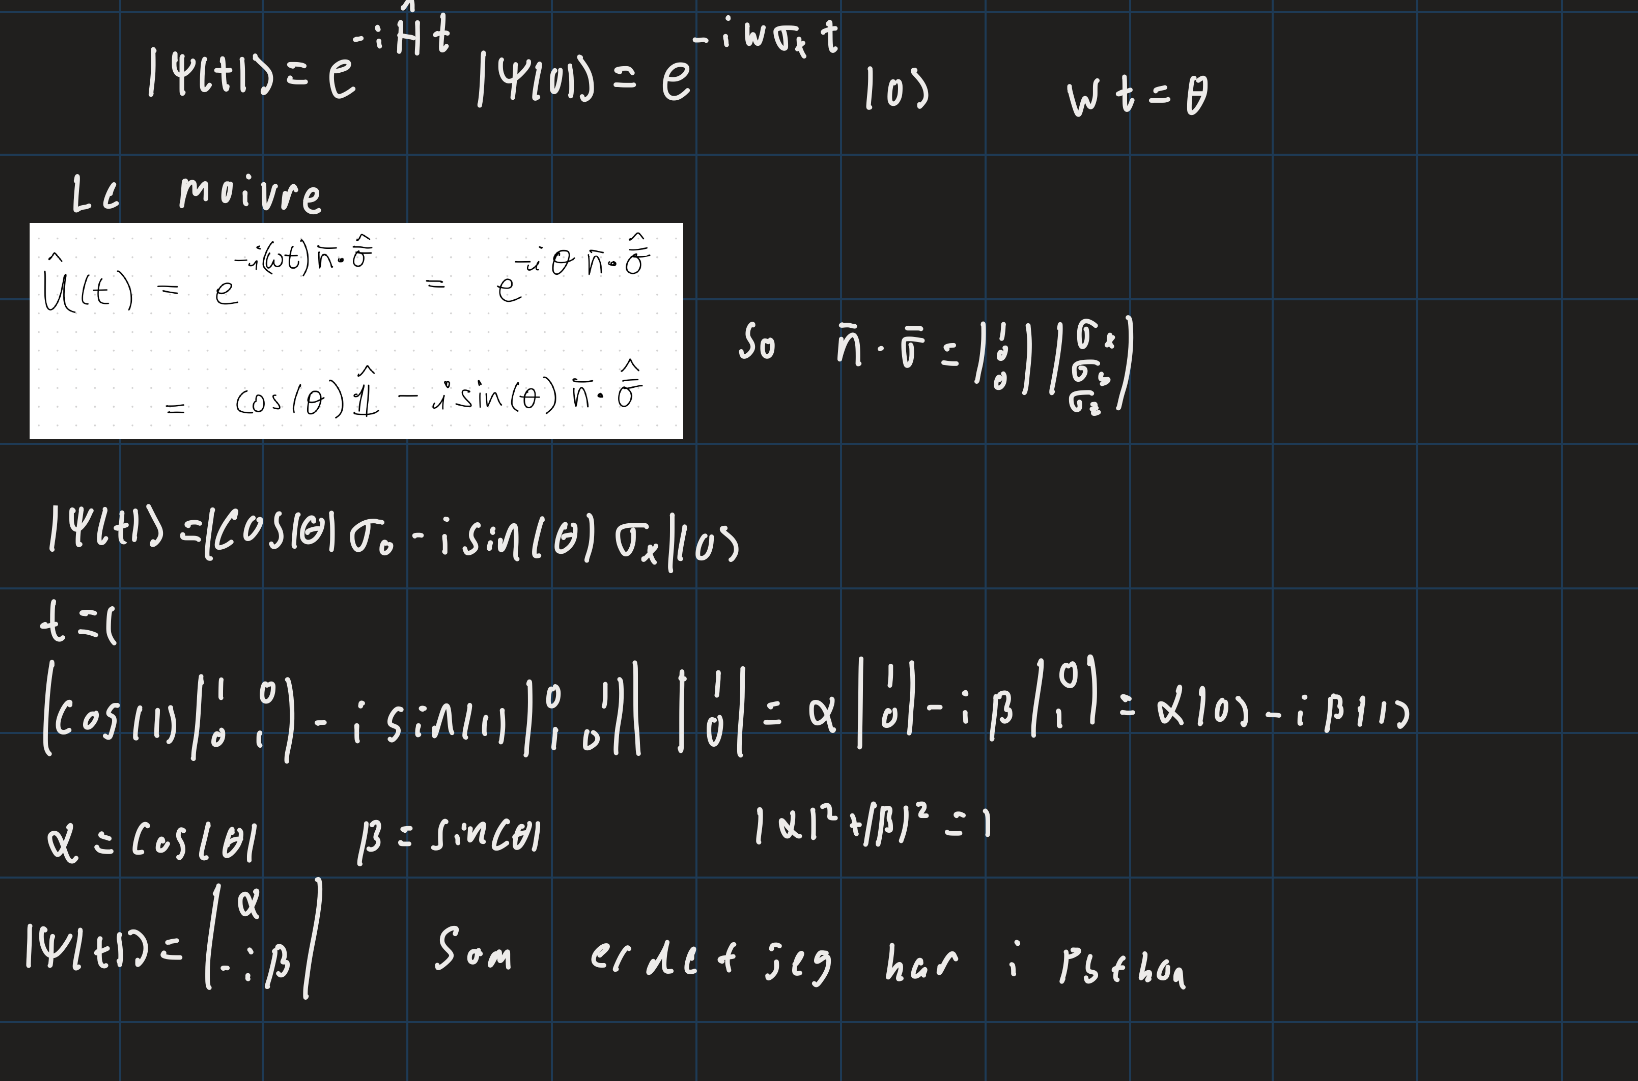

In [43]:
#Q 1.2

In [44]:
# med qutip giver problemer med sympy inden
tlist = np.linspace(0, np.pi/w, 10)

r = np.array([
    [expect(S, (-1j*H*t).expm() * psi_0) for S in (sigmax(), sigmay(), sigmaz())] #tager expectation value af sigmax, sigmay, sigmaz for hver t ift. psi_t
    for t in tlist
])                      # form (200, 3)
print(np.round(r[:10], 3)) # printer  de første 10 rækker af r med 3 decimaler

NameError: name 'H' is not defined

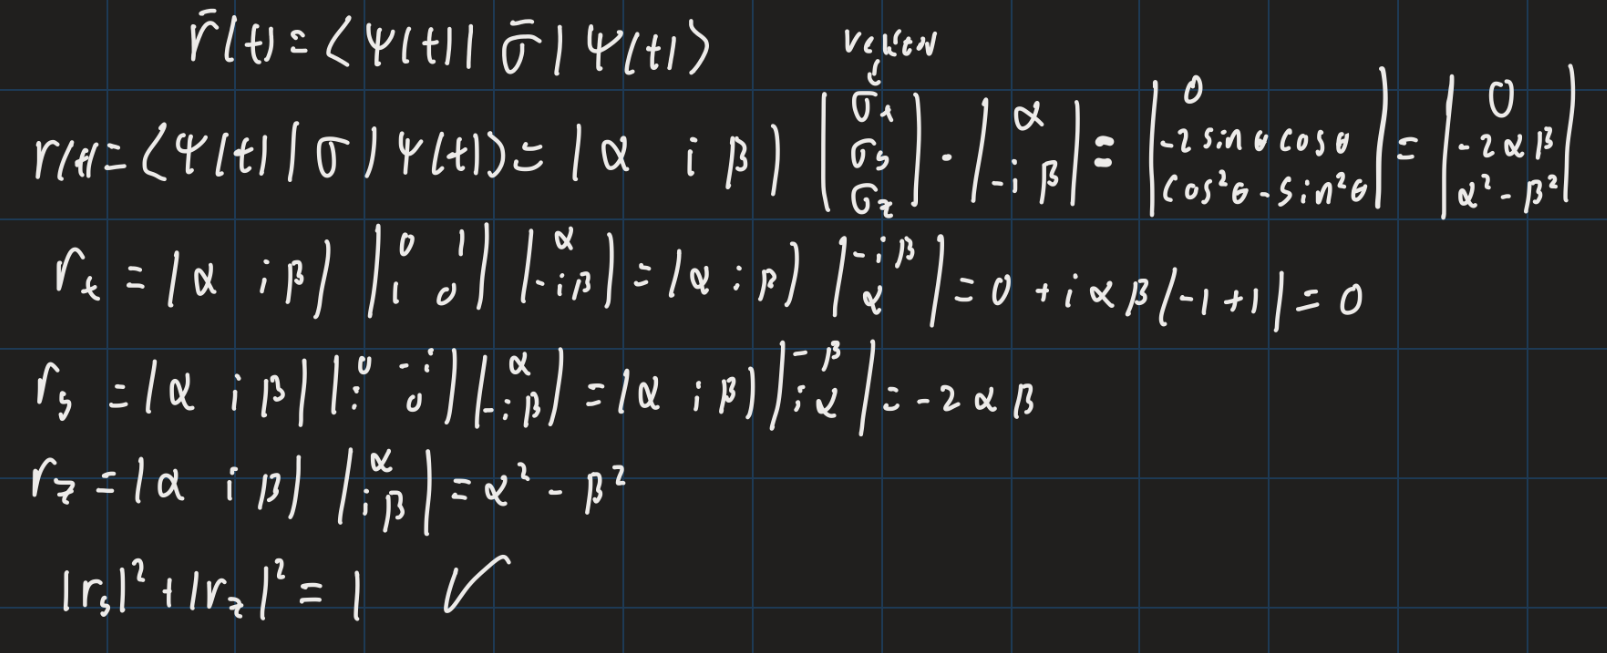

## 1.3 – Plot af Bloch-vektorens bane på enhedskuglen

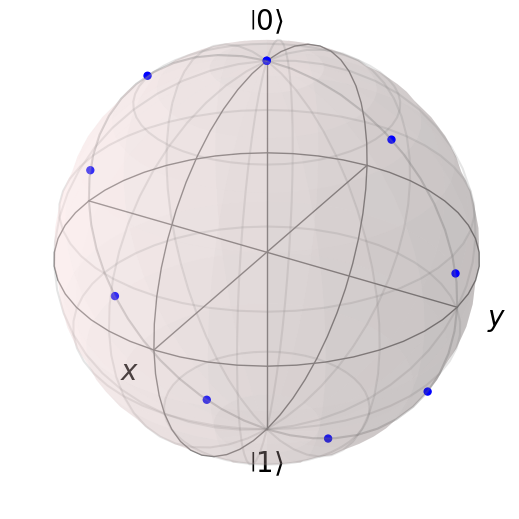

In [ ]:
from qutip import Bloch
b = Bloch()
b.add_points(r.T)     # .T fordi Bloch vil have (3, N), ikke (N, 3)
b.show()

Roterer rundt i X planet, så det er en cirkel i YZ planet starter og slutter i (0,0,1) en periode er pi grader.
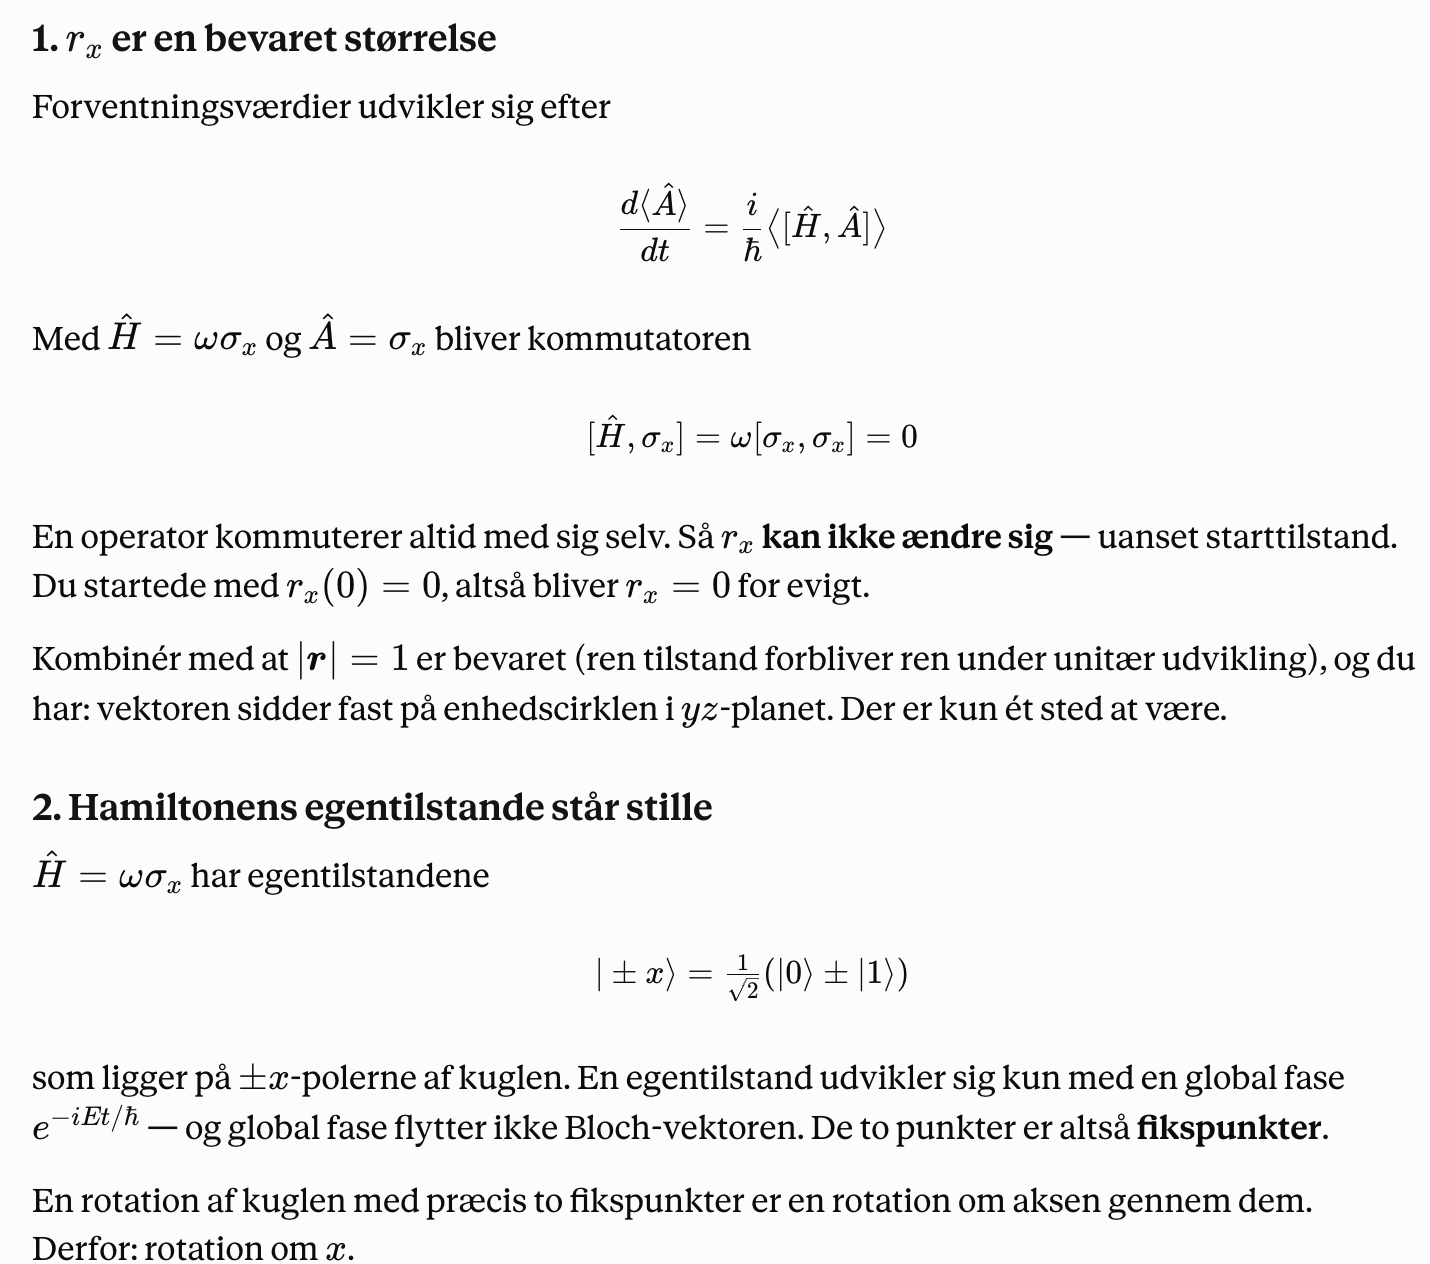 

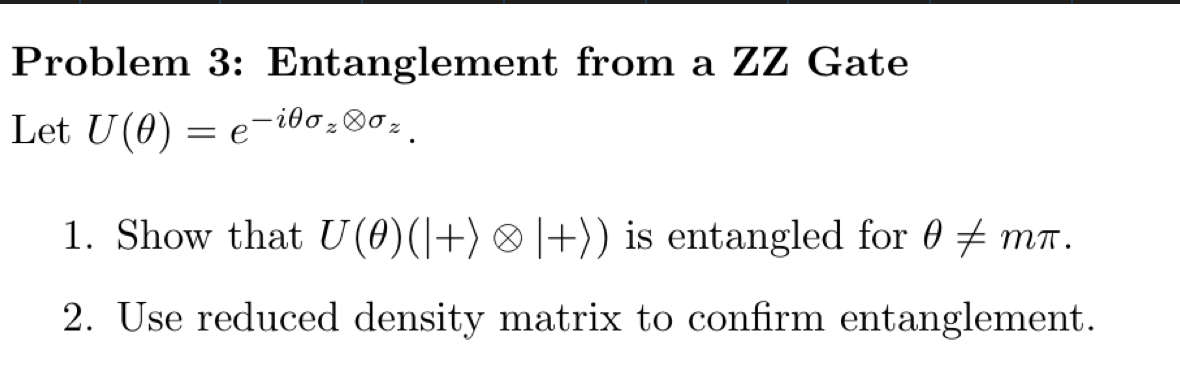
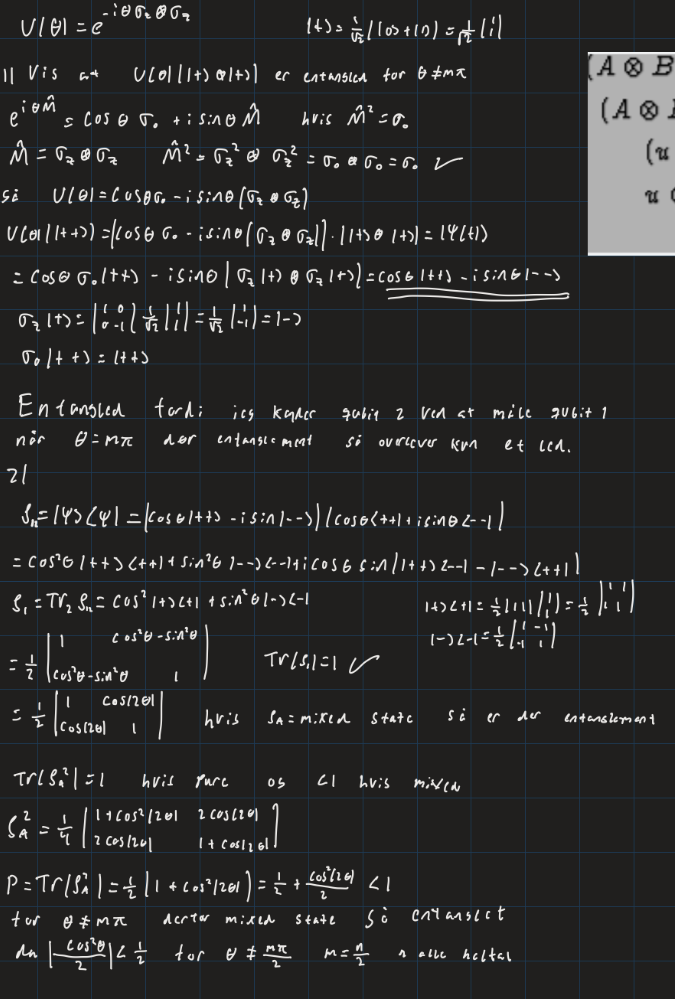

In [ ]:
from qutip import tensor, entropy_vn, concurrence

plus  = (basis(2,0) + basis(2,1)).unit() # unit sørger for at vektoren bliver normaliseret, så den har norm 1
minus = (basis(2,0) - basis(2,1)).unit()
ZZ    = tensor(sigmaz(), sigmaz()) # min M matrice jeg er givet
II    = tensor(qeye(2), qeye(2))

def psi(theta):
    return (-1j*theta*ZZ).expm() * tensor(plus, plus) #de moivre operatoren tensor plus plus er min tilstand.

In [ ]:
psi(np.pi/4) # psi af theta=pi/4

Quantum object: dims=[[2, 2], [1]], shape=(4, 1), type='ket', dtype=Dense
Qobj data =
[[0.35355339-0.35355339j]
 [0.35355339+0.35355339j]
 [0.35355339+0.35355339j]
 [0.35355339-0.35355339j]]

rigtig dimension skal have 4 rækker fordi det er 2 qubits passer med det analytise resultat der giver cos(ø)(++)-isin(ø)(--).
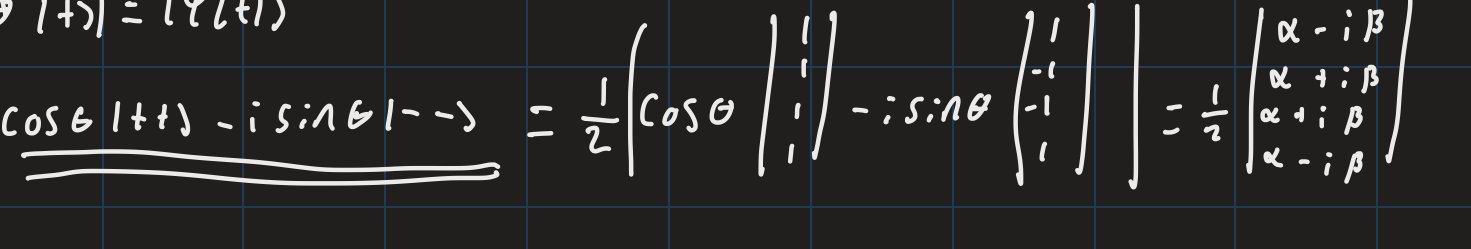

In [ ]:
def diagnose(theta):
    p   = psi(theta) # min tilstand ved theta
    rho = p.ptrace(0)                     # spor qubit 2 ud behold qubit 1 p.ptrace(1) ville være spor qubit 1 ud behold qubit 2
    P   = (rho*rho).tr().real # tager trace af rho^2 og tager den reelle del for at undersøge om det er en ren tilstand. Hvis P=1 er det en ren tilstand, hvis P<1 er det en blandet tilstand.
    return P, entropy_vn(rho, base=2), concurrence(p)

for th in [0, np.pi/8, np.pi/4, 3*np.pi/8, np.pi/2]: # vinklerne theta som jeg vil undersøge
    P, S, C = diagnose(th)
    print(f"theta = {th/np.pi:5.3f} pi   P = {P:.4f}   S = {S:.4f}   C = {C:.4f}")

theta = 0.000 pi   P = 1.0000   S = 0.0000   C = 0.0000
theta = 0.125 pi   P = 0.7500   S = 0.6009   C = 0.7071
theta = 0.250 pi   P = 0.5000   S = 1.0000   C = 1.0000
theta = 0.375 pi   P = 0.7500   S = 0.6009   C = 0.7071
theta = 0.500 pi   P = 1.0000   S = 0.0000   C = 0.0000


Bekræftelse på den er blandet.

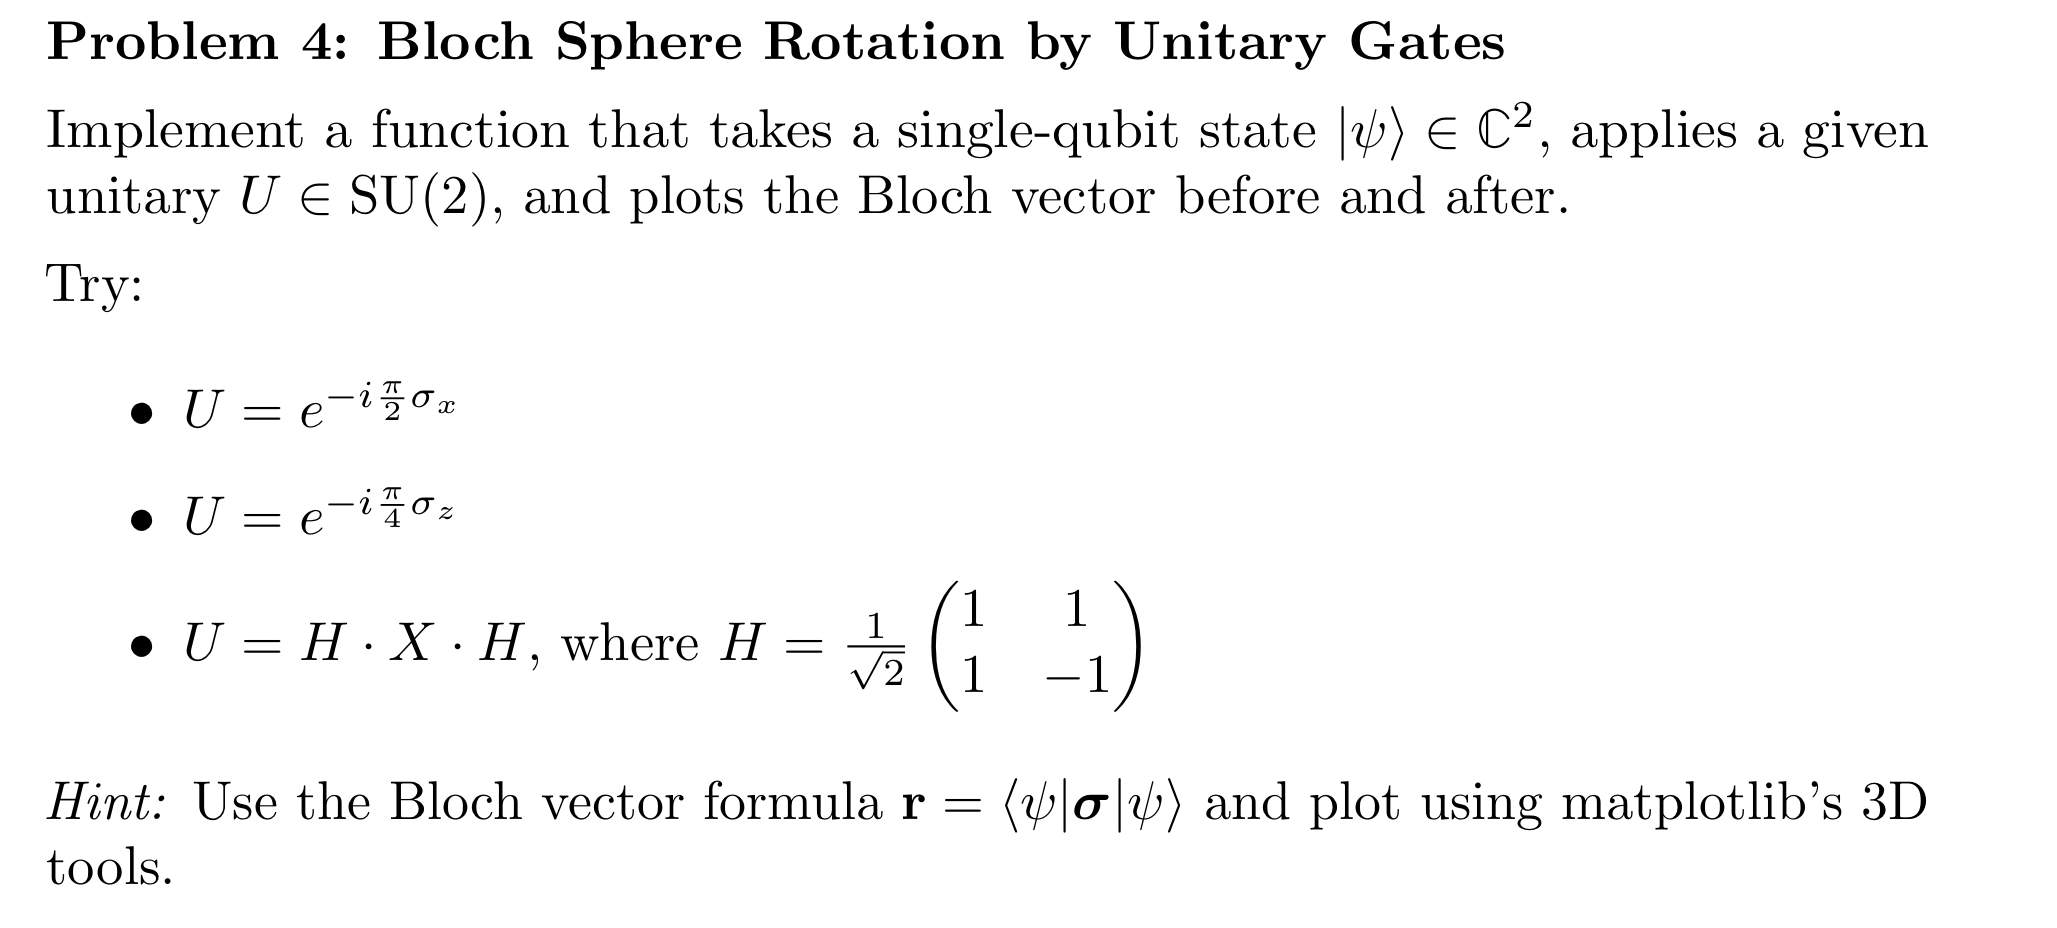

In [ ]:
from qutip import Qobj
H_gate = Qobj(np.array([[1, 1], [1, -1]]) / np.sqrt(2))
X=sx
psi_0 = np.sqrt(1/2) * (basis(2,0) - basis(2,1))
U_1=(-1j*np.pi * 0.5 * sx).expm() #U_1
U_2=(-1j*np.pi * 0.25 * sz).expm() #U_2
U_3=H_gate*X*H_gate #U_3

In [ ]:
def psi_t(U, psi_0): #bestemmer tilstanden efter at have anvendt gate U på psi_0
    return U * psi_0

def bloch_vector(psi):
    return np.array([expect(S, psi) for S in (sigmax(), sigmay(), sigmaz())]) # bloch-vektor for en given tilstand psi


U_1:  [-1.  0.  0.]  ->  [-1.  0.  0.]


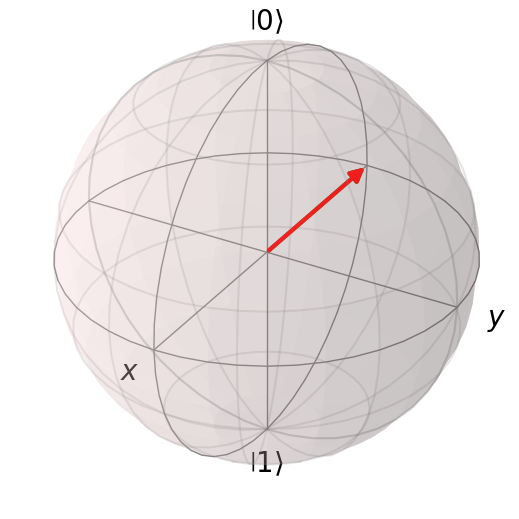

U_2:  [-1.  0.  0.]  ->  [-0. -1.  0.]


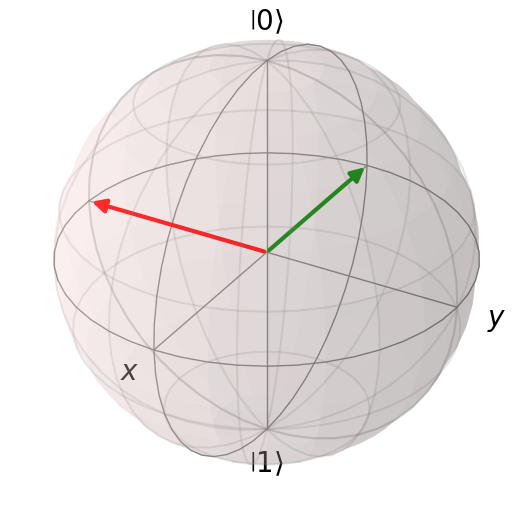

U_3:  [-1.  0.  0.]  ->  [1. 0. 0.]


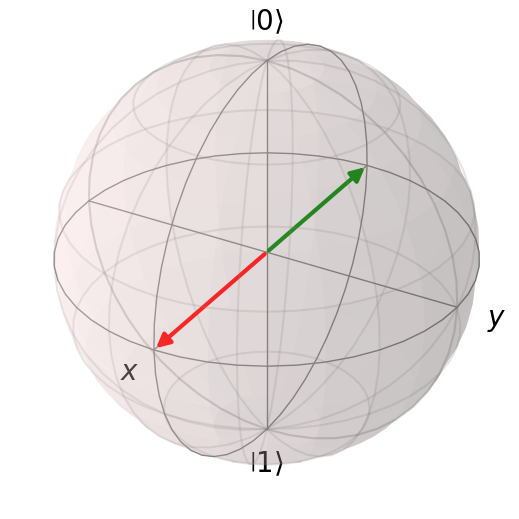

In [ ]:
def vis(U, psi_0, navn=''):
    r0 = bloch_vector(psi_0)
    r1 = bloch_vector(psi_t(U, psi_0))
    print(f"{navn}:  {np.round(r0,3)}  ->  {np.round(r1,3)}")

    b = Bloch() # opretter en Bloch-sfære
    b.add_vectors(r0) # tilføjer vektoren r0 til Bloch-sfæren
    b.add_vectors(r1) # tilføjer vektoren r1 til Bloch-sfæren
    b.vector_color = ['g', 'r']
    b.show()

vis(U_1, psi_0, 'U_1')
vis(U_2, psi_0,  'U_2')    # |+⟩, ikke |0⟩ — ellers sker der intet
vis(U_3, psi_0,  'U_3')

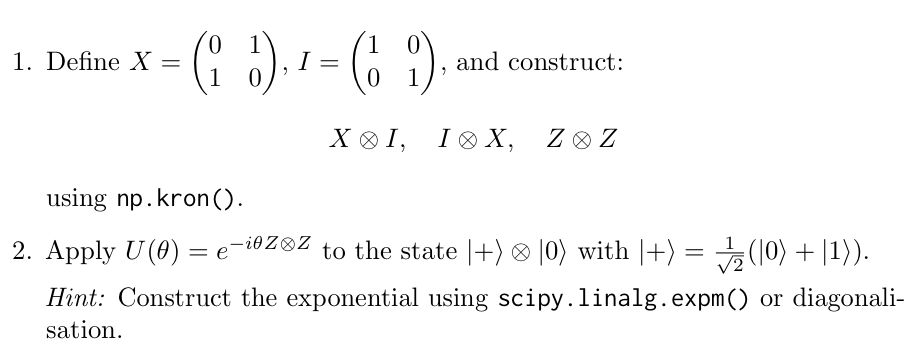

In [ ]:
X_q=sx
Z_q=sz
I_q=qeye(2)
X_n=np.array([[0,1],[1,0]])
I_n=np.array([[1,0],[0,1]])
print(np.kron(X_n,I_n)) # np.kron laver tensorproduktet af X og I, som er det samme som tensor(X,I) i qutip. np.kron er en numpy funktion og forstår ikke qutip objekter, derfor bruger vi tensor(X,I) i qutip.
print(tensor(X_q,I_q)) # tensorproduktet af X og I i qutip

[[0 0 1 0]
 [0 0 0 1]
 [1 0 0 0]
 [0 1 0 0]]
Quantum object: dims=[[2, 2], [2, 2]], shape=(4, 4), type='oper', dtype=CSR, isherm=True
Qobj data =
[[0. 0. 1. 0.]
 [0. 0. 0. 1.]
 [1. 0. 0. 0.]
 [0. 1. 0. 0.]]


In [ ]:
theta = (0, np.pi, 300)
plus=np.sqrt(1/2) * (basis(2,0) + basis(2,1)) # |+> state
psi_0=tensor(plus,ket0)

for th in [0, np.pi/8, np.pi/4, 3*np.pi/8, np.pi/2]:
    U = (-1j * th * ZZ).expm()          # NB: inde i løkken
    print(f"--- theta = {th/np.pi:.3f} pi ---")
    print(np.round(psi_t(U, psi_0)[:5], 2)) # printer  de første 5 rækker af r med 3 decimaler

--- theta = 0.000 pi ---
[[0.71+0.j]
 [0.  +0.j]
 [0.71+0.j]
 [0.  +0.j]]
--- theta = 0.125 pi ---
[[0.65-0.27j]
 [0.  +0.j  ]
 [0.65+0.27j]
 [0.  +0.j  ]]
--- theta = 0.250 pi ---
[[0.5-0.5j]
 [0. +0.j ]
 [0.5+0.5j]
 [0. +0.j ]]
--- theta = 0.375 pi ---
[[0.27-0.65j]
 [0.  +0.j  ]
 [0.27+0.65j]
 [0.  +0.j  ]]
--- theta = 0.500 pi ---
[[0.-0.71j]
 [0.+0.j  ]
 [0.+0.71j]
 [0.+0.j  ]]


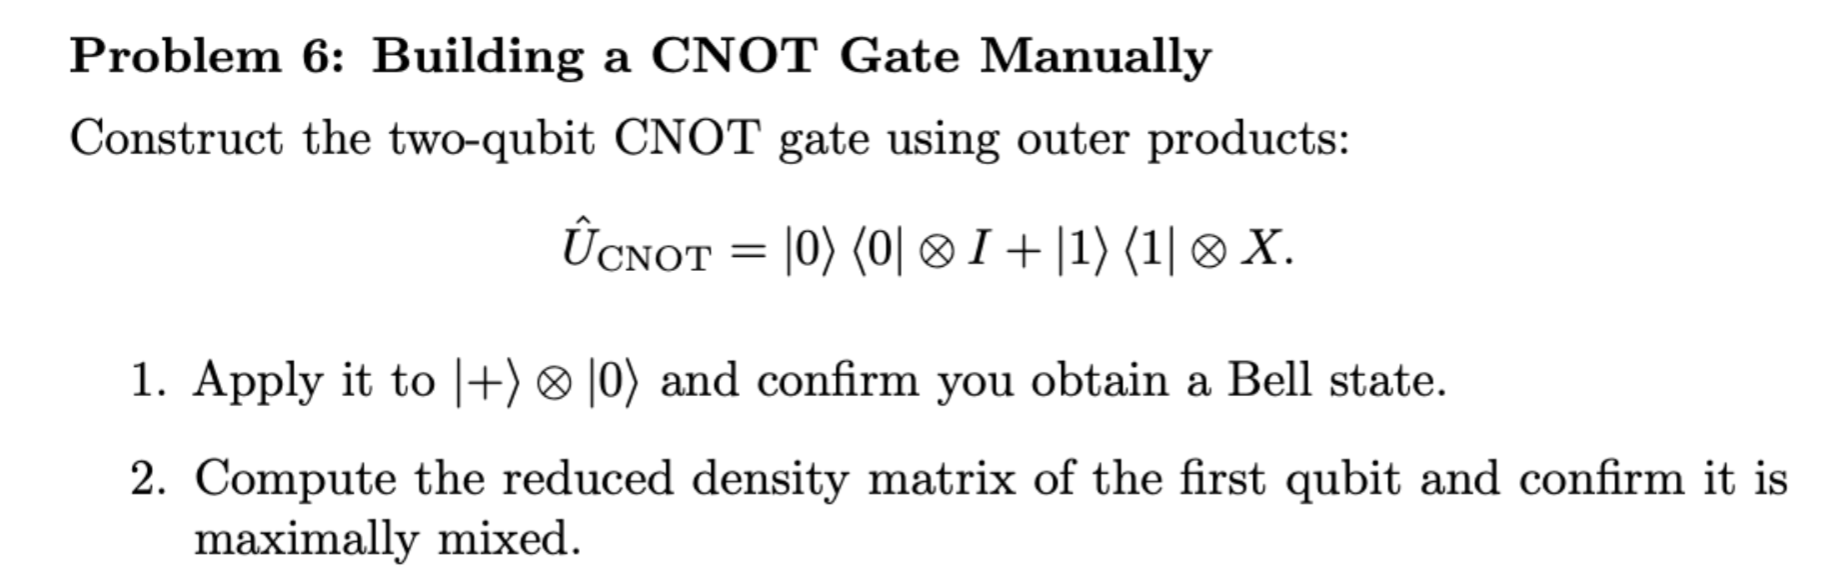

In [ ]:
U_CNOT= tensor(ket0 * ket0.dag(), qeye(2)) + tensor(ket1 * ket1.dag(), sx) # CNOT gate operatoren
print(U_CNOT) # printer CNOT gate operatoren

Quantum object: dims=[[2, 2], [2, 2]], shape=(4, 4), type='oper', dtype=CSR, isherm=True
Qobj data =
[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 0. 1.]
 [0. 0. 1. 0.]]


In [ ]:
psi_0=tensor(plus,ket0)
psi_1=U_CNOT*psi_0 # anvender CNOT gate på psi_0

In [ ]:
def density_matrix(psi):
    return psi * psi.dag() # laver density matrixen rho=|psi><psi|

def reduced_density_matrix(psi, qubit):
    return density_matrix(psi).ptrace(qubit) # spor qubit ud og behold den anden qubit
reduced_density_matrix(psi_1, 0) # spor qubit 2 ud og behold qubit 1


Quantum object: dims=[[2], [2]], shape=(2, 2), type='oper', dtype=CSR, isherm=True
Qobj data =
[[0.5 0. ]
 [0.  0.5]]

Som netop er 1/2 I som betyder det er maksimalt blandet entropien er maksimeret. Dvs. entanglement.

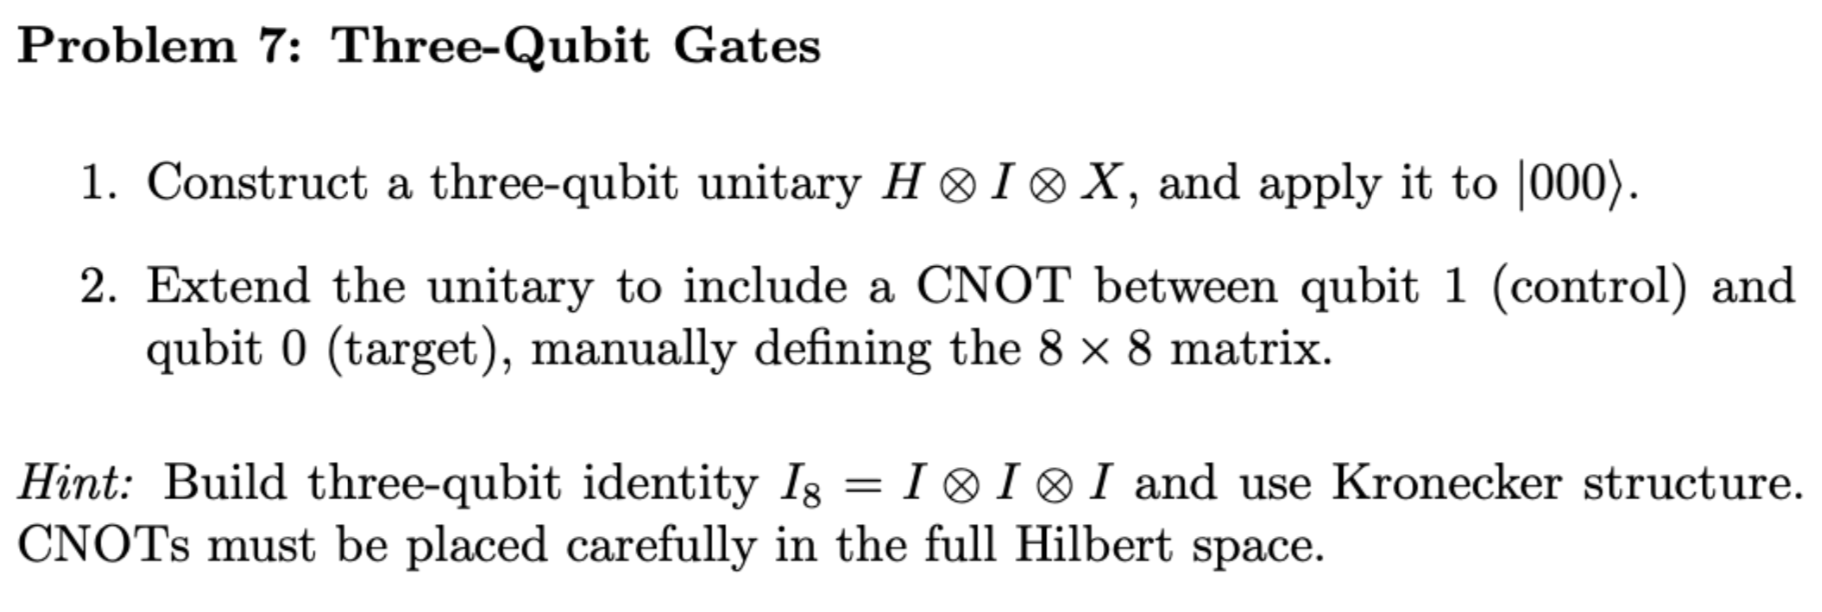

In [ ]:
U_three = tensor(H_gate, qeye(2), sx )
psi_0= tensor(ket0,ket0,ket0)
U_three*psi_0 # anvender U_three gate på psi_0


Quantum object: dims=[[2, 2, 2], [1]], shape=(8, 1), type='ket', dtype=Dense
Qobj data =
[[0.        ]
 [0.70710678]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.70710678]
 [0.        ]
 [0.        ]]

Den passer 1/sqrt(2) (|001> + |101>)
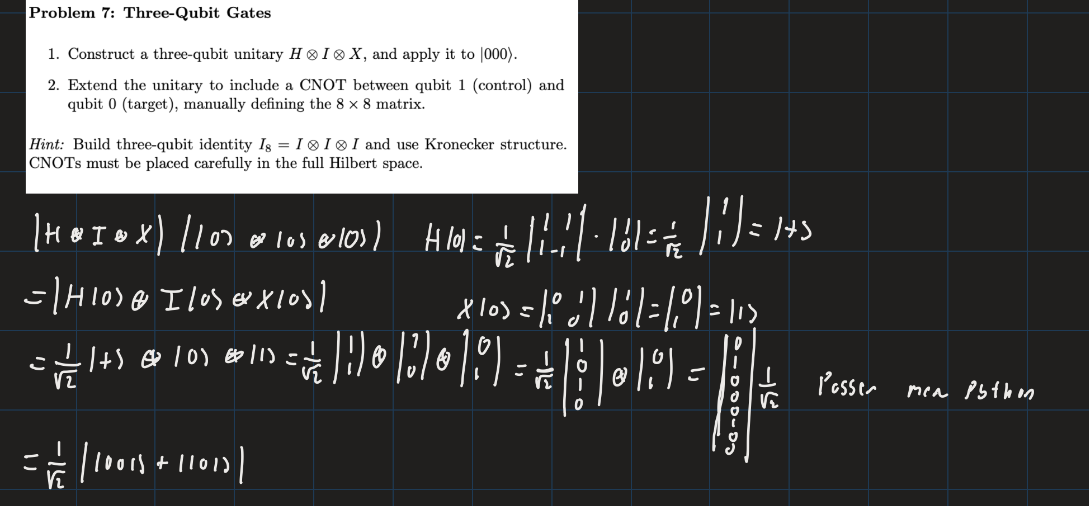

In [ ]:
CNOT_10=tensor(qeye(2),ket0*ket0.dag(),qeye(2)) + tensor(X,ket1*ket1.dag(),qeye(2))

In [ ]:
CNOT_10

Quantum object: dims=[[2, 2, 2], [2, 2, 2]], shape=(8, 8), type='oper', dtype=CSR, isherm=True
Qobj data =
[[1. 0. 0. 0. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 1. 0.]
 [0. 0. 0. 0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 1. 0. 0. 0.]
 [0. 0. 0. 0. 0. 1. 0. 0.]
 [0. 0. 1. 0. 0. 0. 0. 0.]
 [0. 0. 0. 1. 0. 0. 0. 0.]]

In [ ]:
print(CNOT_10 * tensor(ket1,ket0,ket1)) # anvender CNOT_10 gate på |010>
print(tensor(ket1,ket0,ket1)) # anvender CNOT_10 gate på |011>
#intet sker fordi qubit 1 som er controle er i tilstanden |0> og derfor sker der ingen ændring på qubit 0.

Quantum object: dims=[[2, 2, 2], [1]], shape=(8, 1), type='ket', dtype=Dense
Qobj data =
[[0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [1.]
 [0.]
 [0.]]
Quantum object: dims=[[2, 2, 2], [1]], shape=(8, 1), type='ket', dtype=Dense
Qobj data =
[[0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [1.]
 [0.]
 [0.]]


In [ ]:
print(CNOT_10 * tensor(ket1,ket1,ket1)) # anvender CNOT_10 gate på |111> der bliver til |011>
print(tensor(ket1,ket1,ket1)) #
#qubit 0 som er target bliver ændret fordi qubit 1 som er control er i tilstanden |1> og derfor sker der en ændring på qubit 0.

Quantum object: dims=[[2, 2, 2], [1]], shape=(8, 1), type='ket', dtype=Dense
Qobj data =
[[0.]
 [0.]
 [0.]
 [1.]
 [0.]
 [0.]
 [0.]
 [0.]]
Quantum object: dims=[[2, 2, 2], [1]], shape=(8, 1), type='ket', dtype=Dense
Qobj data =
[[0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [1.]]


In [ ]:
U_7=CNOT_10*U_three
U_7

Quantum object: dims=[[2, 2, 2], [2, 2, 2]], shape=(8, 8), type='oper', dtype=CSR, isherm=False
Qobj data =
[[ 0.          0.70710678  0.          0.          0.          0.70710678
   0.          0.        ]
 [ 0.70710678  0.          0.          0.          0.70710678  0.
   0.          0.        ]
 [ 0.          0.          0.          0.70710678  0.          0.
   0.         -0.70710678]
 [ 0.          0.          0.70710678  0.          0.          0.
  -0.70710678  0.        ]
 [ 0.          0.70710678  0.          0.          0.         -0.70710678
   0.          0.        ]
 [ 0.70710678  0.          0.          0.         -0.70710678  0.
   0.          0.        ]
 [ 0.          0.          0.          0.70710678  0.          0.
   0.          0.70710678]
 [ 0.          0.          0.70710678  0.          0.          0.
   0.70710678  0.        ]]

In [ ]:
U_7*tensor(ket0,ket0,ket0) # anvender U_7 gate på |000> der bliver til en superposition af 010 og 101.
# her gør CNOT gaten ikke noget kun U_three gate gør noget.

Quantum object: dims=[[2, 2, 2], [1]], shape=(8, 1), type='ket', dtype=Dense
Qobj data =
[[0.        ]
 [0.70710678]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.70710678]
 [0.        ]
 [0.        ]]

In [ ]:
U_7*tensor(ket0,ket1,ket0) # anvender U_7 gate på |010 nu gør både CNOT og U_three gate noget.

Quantum object: dims=[[2, 2, 2], [1]], shape=(8, 1), type='ket', dtype=Dense
Qobj data =
[[0.        ]
 [0.        ]
 [0.        ]
 [0.70710678]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.70710678]]

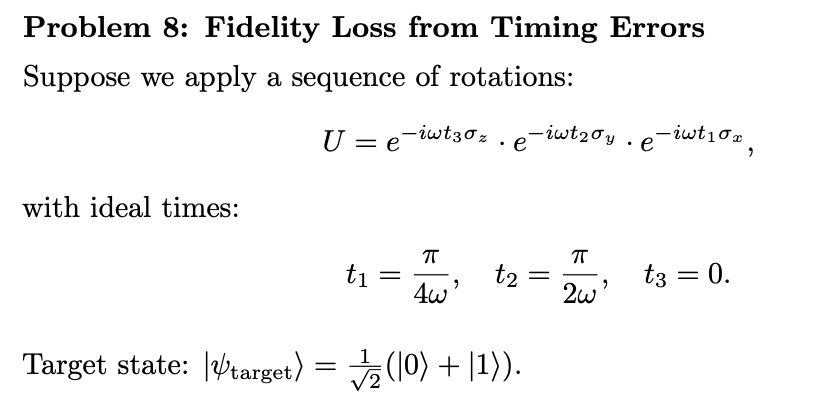

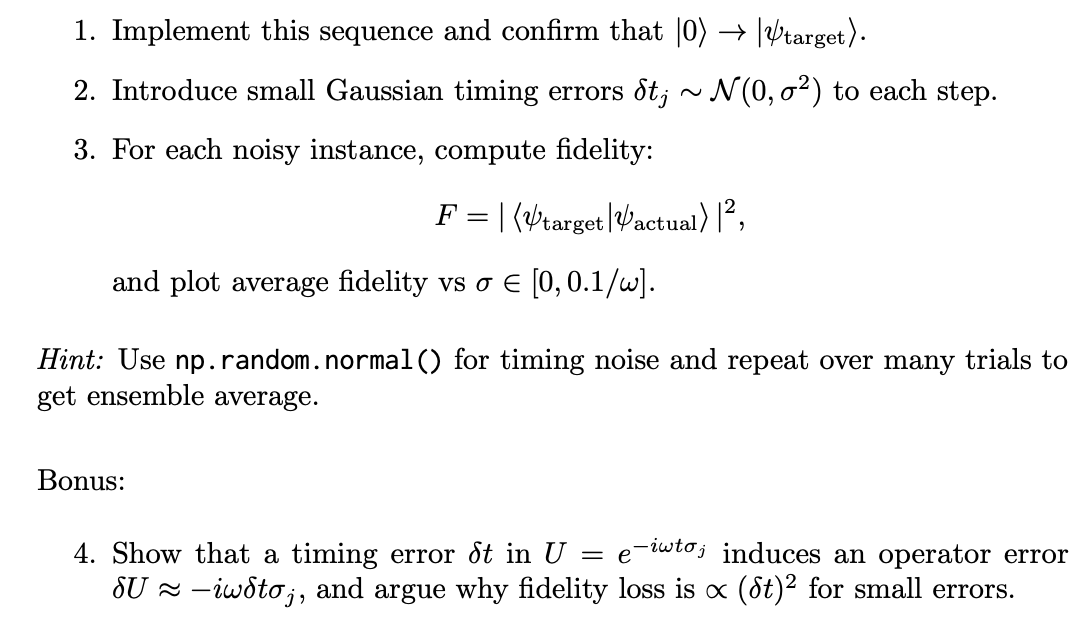

In [ ]:
th_3=0
th_2=np.pi/2
th_1=np.pi/4
U_8=(-1j*th_3*sz).expm()*(-1j*th_2*sy).expm()*(-1j*th_1*sx).expm()

In [ ]:
U_8

Quantum object: dims=[[2], [2]], shape=(2, 2), type='oper', dtype=Dense, isherm=False
Qobj data =
[[ 0.        +0.70710678j -0.70710678+0.j        ]
 [ 0.70710678+0.j          0.        -0.70710678j]]

In [ ]:
print(U_8*ket0)
print(1/np.sqrt(2)*(ket0+ket1))
#U*ket0 giver 1/sqrt(2)(|0>-|1>)

Quantum object: dims=[[2], [1]], shape=(2, 1), type='ket', dtype=Dense
Qobj data =
[[0.        +0.70710678j]
 [0.70710678+0.j        ]]
Quantum object: dims=[[2], [1]], shape=(2, 1), type='ket', dtype=Dense
Qobj data =
[[0.70710678]
 [0.70710678]]


In [ ]:
def U_noise(sigma):
    d1, d2, d3 = np.random.normal(0, sigma, 3)     # tre uafhængige træk
    return ( (-1j*(th_3+d3)*sz).expm()
           * (-1j*(th_2+d2)*sy).expm()
           * (-1j*(th_1+d1)*sx).expm() )

def fidelity(psi1, psi2):
    return abs((psi1.dag() * psi2)) ** 2 # beregner fidelity mellem to tilstande psi1 og psi2
psi_tar=U_8*ket0


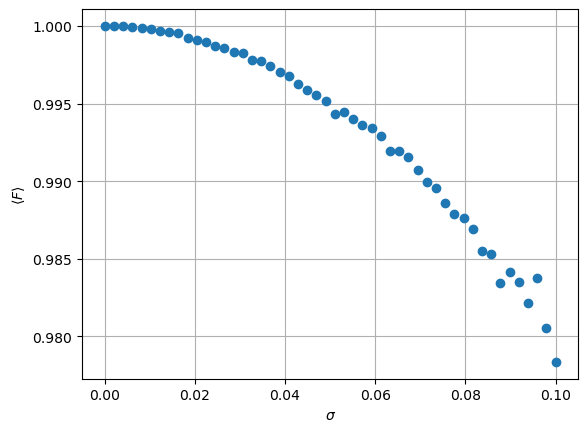

In [ ]:
sigma=np.linspace(0, 0.1, 50) # laver en liste af sigma værdier fra 0 til 0.1 med 50 punkter
N = 500
mid = []
for s in sigma:                                   # ydre: én per sigma
    F = [fidelity(U_noise(s)*ket0, psi_tar)      # indre: N træk
         for _ in range(N)]
    mid.append(np.mean(F))

plt.plot(sigma, mid, 'o')
plt.xlabel(r'$\sigma$'); plt.ylabel(r'$\langle F\rangle$'); plt.grid(True)
plt.show()

Plottet viser at fidelity falder med støj, det er hverken en lineær eller eksponentiel funktion, men det er en funktion der er omvendt proportionel med støjens størrelse. Dvs. jo større støj, jo mindre fidelity. Det er en parabel.

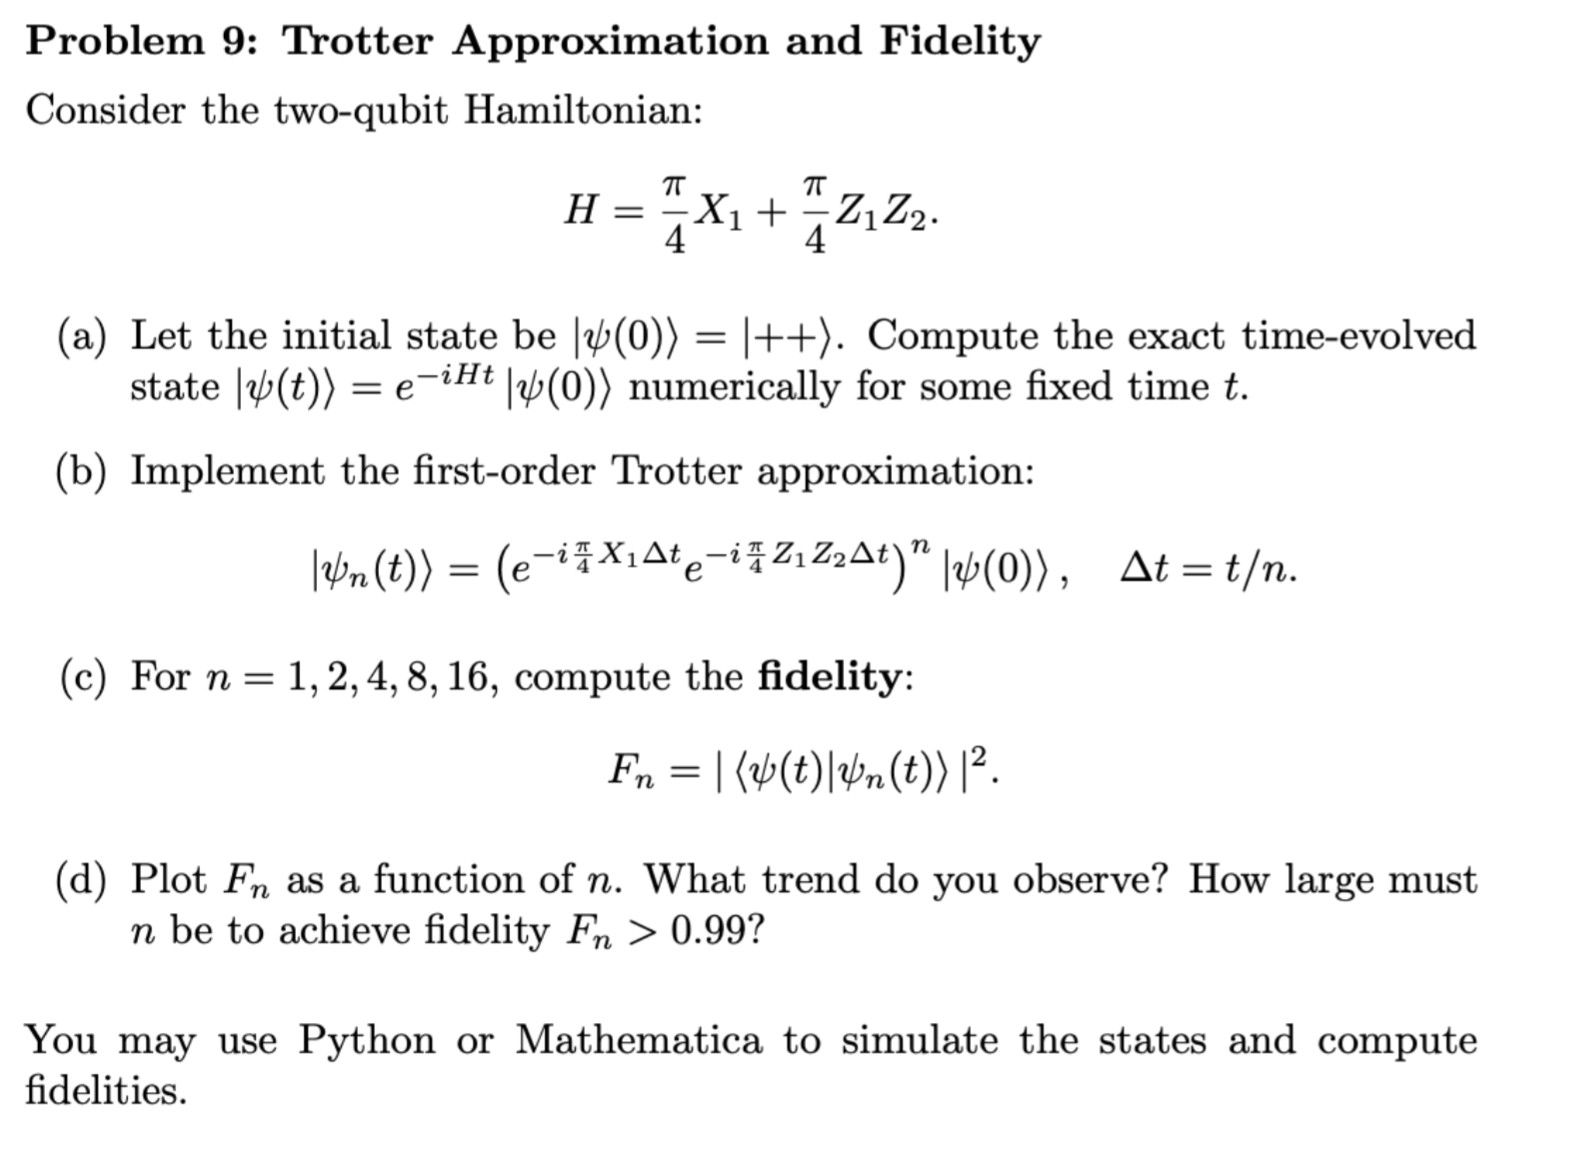
Indekserne angiver hvilken qubit de virker på H er derfor rigtigt det her:
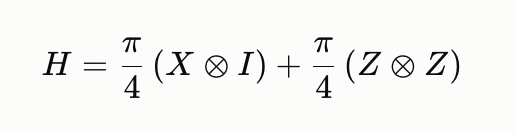

In [ ]:
H_9=np.pi/4 * tensor(X,I)+ np.pi/4*tensor(sz,sz)
psi_0=tensor(plus,plus)
H_9

Quantum object: dims=[[2, 2], [2, 2]], shape=(4, 4), type='oper', dtype=CSR, isherm=True
Qobj data =
[[ 0.78539816  0.          0.78539816  0.        ]
 [ 0.         -0.78539816  0.          0.78539816]
 [ 0.78539816  0.         -0.78539816  0.        ]
 [ 0.          0.78539816  0.          0.78539816]]

In [ ]:
def U(H,t):
    return (-1j * H * t).expm()   # tidsudviklingsoperatoren U(t) -1j betyder -i 1j er i.

def psi_t(U, psi_0):
    return U * psi_0

In [ ]:
t=1/4*np.pi
U_9=U(H_9,t ) # anvender U gate på H_9 med t=1
psi_t(U_9, psi_0) # anvender U gate på psi_0 med t=1

Quantum object: dims=[[2, 2], [1]], shape=(4, 1), type='ket', dtype=Dense
Qobj data =
[[0.32151122-5.41535839e-01j]
 [0.32151122-5.55111512e-17j]
 [0.32151122+0.00000000e+00j]
 [0.32151122-5.41535839e-01j]]

In [ ]:
def trotter(H_1,H_2,dt,psi_0,n):
    psi_th= ( (-1j * H_1 * dt).expm() * (-1j * H_2 * dt).expm() )**n * psi_0 # anvender U_dt n gange på psi_0
    return psi_th

In [ ]:
H_1= np.pi/4 * tensor(X,I)
H_2= np.pi/4 *  tensor(sz,sz)
fidelity_l=[]
for n in [1, 2, 4, 8, 16]:
    dt = t / n
    U_th=U(H_9, dt) # anvender U gate på H_9 med dt i stedet for t
    psi_th=trotter(H_1, H_2, dt, psi_0, n) # anvender trotter metoden på U_th med psi_0 og n gange
    psi_tar=psi_t(U_9, psi_0) # anvender U gate på psi_0 med t=1
    fidelity_l.append(fidelity(psi_th, psi_tar)) # beregner fidelity mellem psi_th og psi_tar og tilføjer den til listen fidelity_l


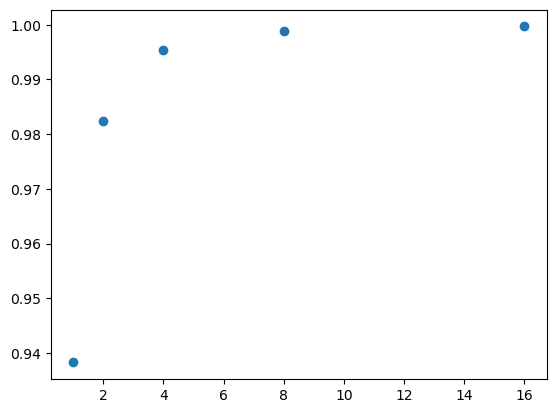

In [ ]:
n=np.array([1, 2, 4, 8, 16])
plt.plot(n, fidelity_l, 'o')

In [ ]:
fidelity_l

[0.9382493312230105,
 0.9824698477305068,
 0.9953545873125637,
 0.9988040440152558,
 0.9996965340750663]

man skal have n=3 for at få over 0,99%

In [ ]:
import scipy.integrate as integrate

In [45]:
def trotter(H_1,H_2,dt,psi_0,n):
    psi_th= ( (-1j * H_1 *w *dt).expm() * (-1j * H_2 * w * dt).expm() )**n * psi_0 
    return psi_th

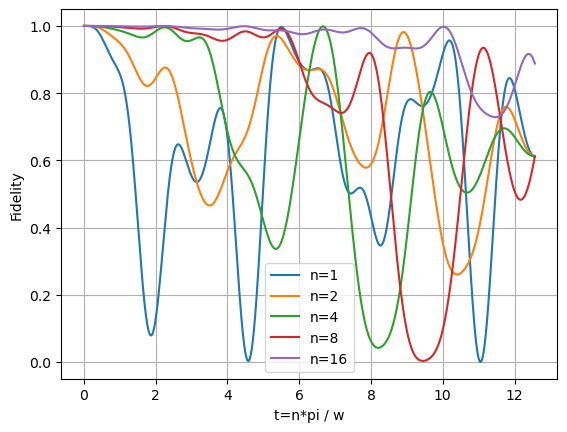

In [46]:
w = 1
t = np.linspace(0, 4*np.pi/w, 1000)
psi_0 = tensor(ket_plus, ket_plus)
M = tensor(sx, I) + tensor(sz, sz)
H_1, H_2 = w*tensor(sx, I), w*tensor(sz, sz)

psi_t = [(-1j*w*ti*M).expm() * psi_0 for ti in t]
for n in [1, 2, 4, 8, 16]:
    fid_data = [abs(trotter(H_1, H_2, ti/n, psi_0, n).overlap(psi_t[i]))**2
                for i, ti in enumerate(t)]
    plt.plot(t, fid_data, label=f'n={n}')
plt.xlabel('t=n*pi / w'); plt.ylabel('Fidelity'); plt.legend(); plt.grid(True); plt.show()


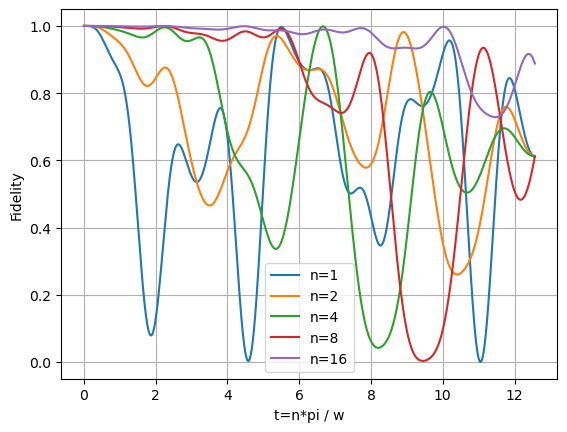

In [47]:
w = 1
t = np.linspace(0, 4*np.pi/w, 1000)
psi_0 = tensor(ket_plus, ket_plus)  
M = tensor(sx, I) + tensor(sz, sz)
H_1, H_2 = w*tensor(sx, I), w*tensor(sz, sz)

psi_t = [(-1j*w*ti*M).expm() * psi_0 for ti in t]

all_fidelity_data = {}


n_values = [1, 2, 4, 8, 16]

for n in n_values:
    fid_data = [abs(trotter(H_1, H_2, ti/n, psi_0, n).overlap(psi_t[i]))**2
                for i, ti in enumerate(t)]
    
    all_fidelity_data[n] = fid_data
    
    plt.plot(t, fid_data, label=f'n={n}')
plt.xlabel('t=n*pi / w')
plt.ylabel('Fidelity')
plt.legend()
plt.grid(True)
plt.show()

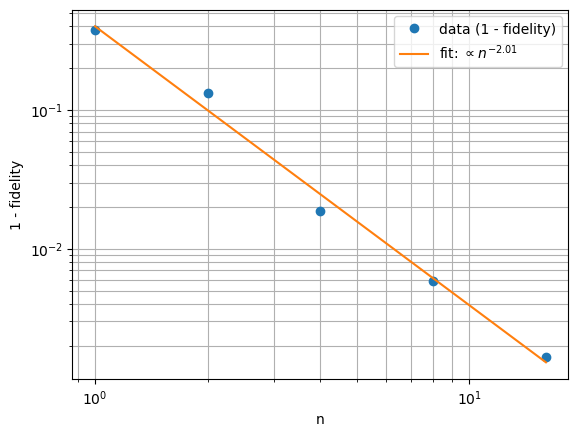

Fittet potens p = 2.009  (p ≈ 2 betyder infidelity ~ 1/n^2)


In [ ]:
n_arr = np.array(n_values)
infidelity = 1 - np.array([np.trapezoid(all_fidelity_data[n], t) * w/np.pi for n in n_values])

# simpelt potens-fit: infidelity ~ C / n^p  <=>  log(infidelity) = log(C) - p*log(n)
coeffs = np.polyfit(np.log(n_arr), np.log(infidelity), 1)
p_fit, C_fit = -coeffs[0], np.exp(coeffs[1])

n_fit = np.linspace(n_arr.min(), n_arr.max(), 100)
fit_curve = C_fit * n_fit**(-p_fit)

plt.loglog(n_arr, infidelity, 'o', label='data (1 - fidelity)')
plt.loglog(n_fit, fit_curve, '-', label=f'fit: $\\propto n^{{-{p_fit:.2f}}}$')
plt.xlabel('n'); plt.ylabel('1 - fidelity'); plt.legend(); plt.grid(True, which='both')
plt.show()

print(f'Fittet potens p = {p_fit:.3f}  (p ≈ 2 betyder infidelity ~ 1/n^2)')

In [122]:
b=np.linspace(0.1, 6, 100) 
n_values = [1, 2,3, 4,6,7, 8,9,10, 16]
t_0values={}
for n in n_values:
    for b_value in b:
        t = np.linspace(0, b_value*np.pi/w, 1000)
        psi_t = [(-1j*w*ti*M).expm() * psi_0 for ti in t]
        all_fidelity_data = {}
        fid_data = [abs(trotter(H_1, H_2, ti/n, psi_0, n).overlap(psi_t[i]))**2 
                    for i, ti in enumerate(t)]
        
        all_fidelity_data[n] = fid_data
        exp_fidelity=np.trapezoid(fid_data, t)  * w/(np.pi*b_value)
        if exp_fidelity < 0.98:  # only print if fidelity is below 0.99
            print(f"t_0={b_value*np.pi/w:.2f}, n={n}, exp fidelity={exp_fidelity:.4f}")
            t_0values[n]=b_value*np.pi/w
            break
       

t_0=0.69, n=1, exp fidelity=0.9784
t_0=1.25, n=2, exp fidelity=0.9741
t_0=1.62, n=3, exp fidelity=0.9782
t_0=3.50, n=4, exp fidelity=0.9787
t_0=4.06, n=6, exp fidelity=0.9786
t_0=4.99, n=7, exp fidelity=0.9796
t_0=6.31, n=8, exp fidelity=0.9756
t_0=6.49, n=9, exp fidelity=0.9777
t_0=6.87, n=10, exp fidelity=0.9788
t_0=10.80, n=16, exp fidelity=0.9788


In [124]:
n=np.array(list(t_0values.keys()))
t_0=np.array(list(t_0values.values()))

In [128]:
import numpy.polynomial.polynomial as poly
b, m = poly.Polynomial.fit(n, t_0, 1).convert().coef
n_fit=np.linspace(n.min(), n.max(), 100)
fit_curve = m*n_fit

In [129]:
b,m

(np.float64(0.11095030965561037), np.float64(0.688917797731871))

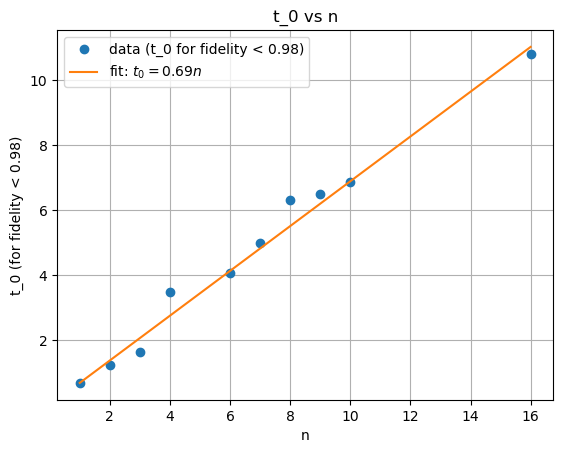

In [131]:
plt.plot(n, t_0, 'o', label='data (t_0 for fidelity < 0.98)')
plt.plot(n_fit, fit_curve, '-', label=f'fit: $t_0 =  {m:.2f} n$')
plt.xlabel('n'); plt.ylabel('t_0 (for fidelity < 0.98)'); plt.grid(True); plt.title('t_0 vs n');plt.legend(); plt.show()